In [ ]:
import pandas as pd
import numpy as np
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import skew
import seaborn as sns
from scipy.stats import boxcox

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score


In [ ]:
heart_data = pd.read_csv('/content/heart disease prediction.csv')

In [ ]:
heart_data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52.0,1,0.0,125.0,212,0.0,1,168,0,1.0,2.0,2.0,3,0
1,53.0,1,0.0,140.0,203,1.0,0,155,1,3.1,0.0,0.0,3,0
2,70.0,1,0.0,145.0,174,0.0,1,125,1,2.6,0.0,NaN,3,0
3,61.0,1,0.0,148.0,203,0.0,1,161,0,0.0,2.0,1.0,3,0
4,62.0,0,0.0,138.0,294,1.0,1,106,0,1.9,1.0,3.0,2,0


In [ ]:
heart_data.shape

(1025, 14)

In [ ]:
heart_data = heart_data.drop('sex', axis=1)


In [ ]:
heart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1022 non-null   float64
 1   cp        1024 non-null   float64
 2   trestbps  1023 non-null   float64
 3   chol      1024 non-null   object 
 4   fbs       1024 non-null   float64
 5   restecg   1025 non-null   int64  
 6   thalach   1023 non-null   object 
 7   exang     1025 non-null   int64  
 8   oldpeak   1025 non-null   float64
 9   slope     1023 non-null   float64
 10  ca        1023 non-null   float64
 11  thal      1025 non-null   int64  
 12  target    1025 non-null   int64  
dtypes: float64(7), int64(4), object(2)
memory usage: 104.2+ KB


In [ ]:
heart_data['chol'] = pd.to_numeric(heart_data['chol'], errors='coerce')
heart_data['thalach'] = pd.to_numeric(heart_data['thalach'], errors='coerce')


In [ ]:
print(heart_data.duplicated().sum())

698


In [ ]:
heart_data = heart_data.drop_duplicates()
print(heart_data.duplicated().sum())

0


In [ ]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
skewness = heart_data[continuous_cols].apply(lambda x: skew(x, nan_policy='omit'))
print("Skewness before Box-Cox:\n", skewness)


Skewness before Box-Cox:
 age         0.041726
trestbps    0.693823
chol        1.096701
thalach    -0.581037
oldpeak     1.266635
dtype: float64


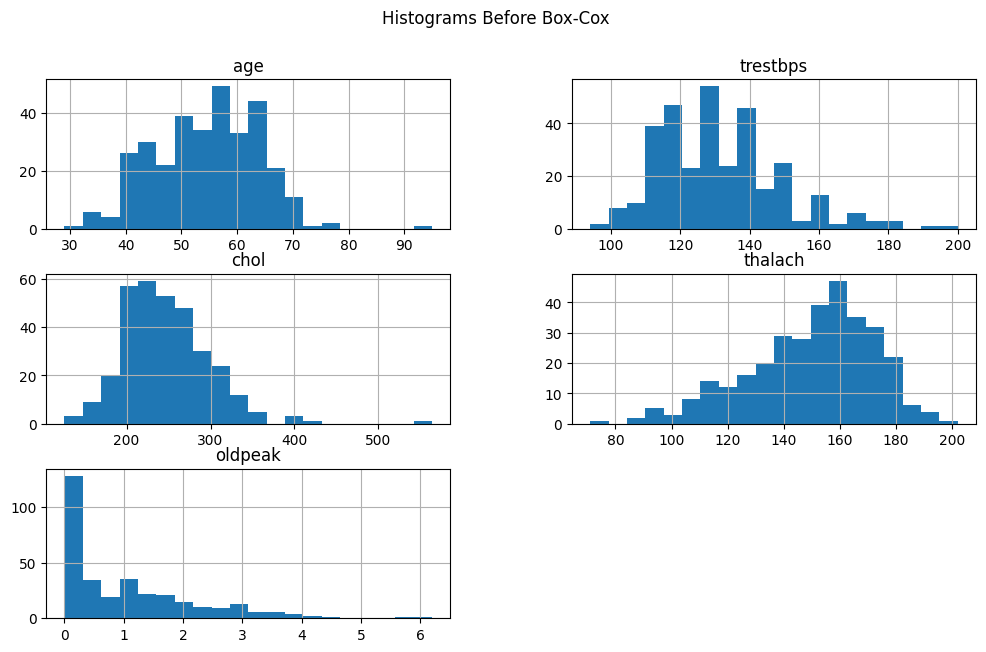

In [ ]:
heart_data[continuous_cols].hist(bins=20, figsize=(12,7))
plt.suptitle("Histograms Before Box-Cox")
plt.show()

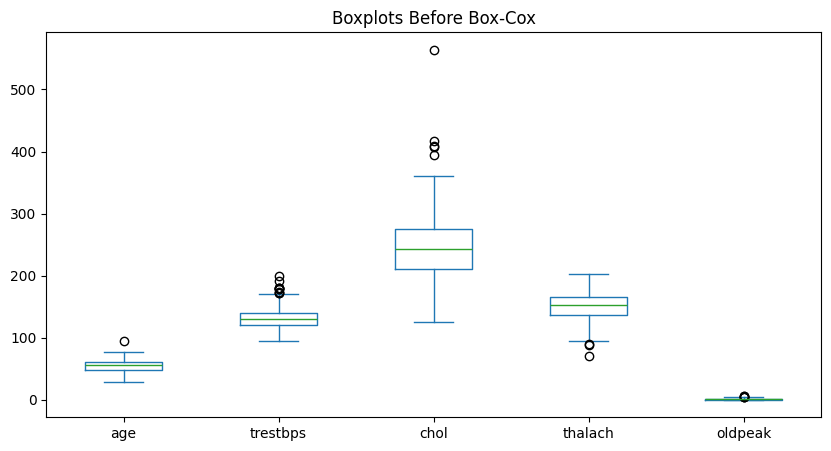

In [ ]:
heart_data[continuous_cols].plot(kind='box', figsize=(10,5))
plt.title("Boxplots Before Box-Cox")
plt.show()

In [ ]:
heart_data_boxcox = heart_data.copy()
lambdas = {}

for col in continuous_cols:

    col_nonan = heart_data_boxcox[col].dropna()
    min_val = col_nonan.min()
    if min_val <= 0:
        col_nonan = col_nonan + abs(min_val) + 1


    transformed, lam = boxcox(col_nonan)
    lambdas[col] = lam


    heart_data_boxcox.loc[col_nonan.index, col] = transformed

print("Lambda values:", lambdas)

Lambda values: {'age': np.float64(0.9237076666067883), 'trestbps': np.float64(-0.7318421423568214), 'chol': np.float64(-0.0979939842493223), 'thalach': np.float64(2.3533840707684086), 'oldpeak': np.float64(-0.5117805400904845)}


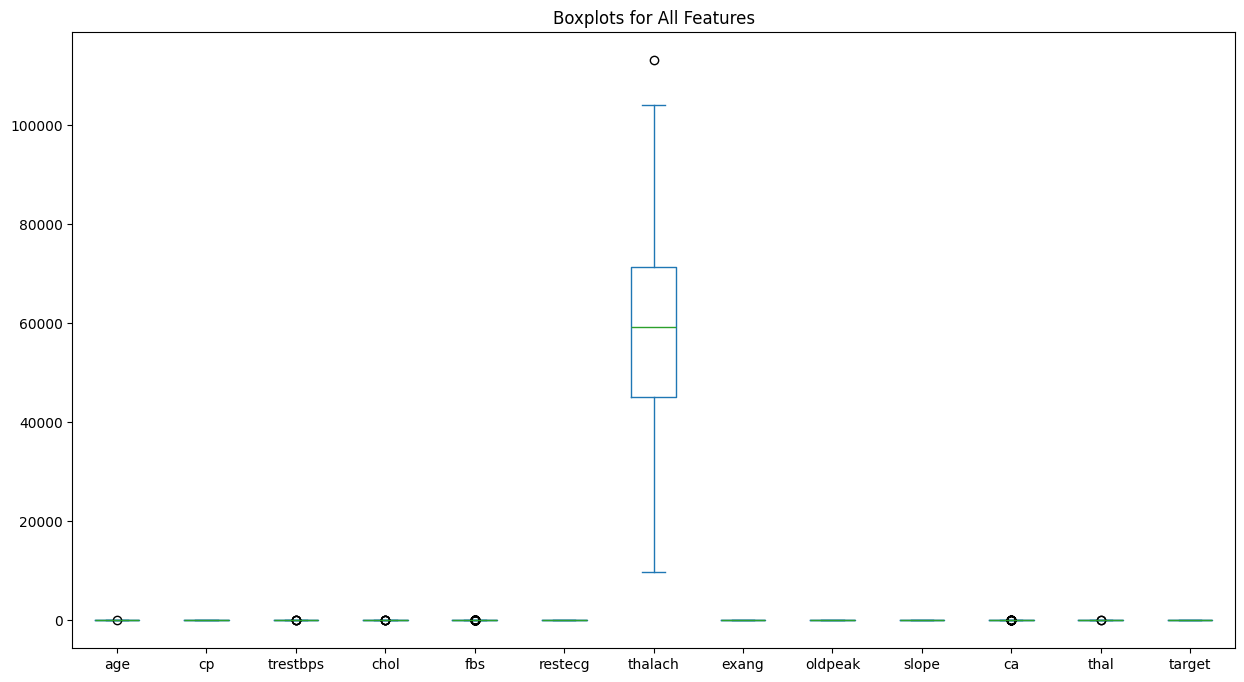

In [ ]:
heart_data_boxcox.plot(kind='box', figsize=(15,8))
plt.title("Boxplots for All Features")
plt.show()


In [ ]:
import numpy as np

heart_data_cleaned = heart_data_boxcox.copy()

for col in continuous_cols:
    Q1 = heart_data_cleaned[col].quantile(0.25)
    Q3 = heart_data_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers = heart_data_cleaned[(heart_data_cleaned[col] < lower_bound) | (heart_data_cleaned[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers detected")


    heart_data_cleaned[col] = np.where(heart_data_cleaned[col] < lower_bound, lower_bound, heart_data_cleaned[col])
    heart_data_cleaned[col] = np.where(heart_data_cleaned[col] > upper_bound, upper_bound, heart_data_cleaned[col])


age: 1 outliers detected
trestbps: 4 outliers detected
chol: 5 outliers detected
thalach: 1 outliers detected
oldpeak: 0 outliers detected


In [ ]:
for col in continuous_cols:
    Q1 = heart_data_cleaned[col].quantile(0.25)
    Q3 = heart_data_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers_after = heart_data_cleaned[(heart_data_cleaned[col] < lower_bound) | (heart_data_cleaned[col] > upper_bound)]
    print(f"{col}: {len(outliers_after)} outliers remaining after capping")


age: 0 outliers remaining after capping
trestbps: 0 outliers remaining after capping
chol: 0 outliers remaining after capping
thalach: 0 outliers remaining after capping
oldpeak: 0 outliers remaining after capping


In [ ]:
print("Missing values per column:")
print(heart_data_cleaned.isnull().sum())



Missing values per column:
age         3
cp          1
trestbps    2
chol        2
fbs         1
restecg     0
thalach     3
exang       0
oldpeak     0
slope       2
ca          2
thal        0
target      0
dtype: int64


In [ ]:
for col in heart_data_cleaned.columns:
    mean_value = heart_data_cleaned[col].mean()
    heart_data_cleaned[col] = heart_data_cleaned[col].fillna(mean_value)


In [ ]:

print("\nMissing values after imputation:")
print(heart_data_cleaned.isnull().sum())


Missing values after imputation:
age         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
x = heart_data_cleaned.drop('target', axis=1)
y = heart_data_cleaned['target']

In [ ]:
print(x)

            age   cp  trestbps      chol  fbs  restecg       thalach  exang  \
0     40.561259  0.0  1.326515  4.167534  0.0        1  73335.134057      0   
1     41.300465  0.0  1.329690  4.141816  1.0        0  60673.056965      1   
2     53.719438  0.0  1.330622  4.049535  0.0        1  36570.994187      1   
3     47.177516  0.0  1.331154  4.141816  0.0        1  66345.775159      0   
4     47.907853  0.0  1.329302  4.357919  1.0        1  24809.745773      0   
...         ...  ...       ...       ...  ...      ...           ...    ...   
906   33.105373  0.0  1.329690  4.205249  0.0        1  84024.817947      0   
971   61.833099  2.0  1.334826  4.129980  1.0        1  67319.656073      0   
974   33.856593  0.0  1.322602  4.164737  0.0        1  66345.775159      0   
1019  36.848474  0.0  1.323176  4.295926  0.0        1  50192.290105      0   
1023  39.079567  0.0  1.322602  4.273525  0.0        0  64422.452170      0   

       oldpeak     slope        ca  thal  
0     0.

In [ ]:
print(y)

0       0
1       0
2       0
3       0
4       0
       ..
906     1
971     1
974     1
1019    1
1023    1
Name: target, Length: 327, dtype: int64


In [ ]:
corr_matrix = x.corr()
print("Correlation Matrix:\n", corr_matrix)

Correlation Matrix:
                age        cp  trestbps      chol       fbs   restecg  \
age       1.000000 -0.028253  0.290780  0.178792  0.126042 -0.106365   
cp       -0.028253  1.000000  0.062740 -0.074102  0.118789  0.029044   
trestbps  0.290780  0.062740  1.000000  0.141588  0.186141 -0.113550   
chol      0.178792 -0.074102  0.141588  1.000000  0.030913 -0.158412   
fbs       0.126042  0.118789  0.186141  0.030913  1.000000 -0.096118   
restecg  -0.106365  0.029044 -0.113550 -0.158412 -0.096118  1.000000   
thalach  -0.410209  0.273576 -0.040409 -0.007050  0.001731  0.046637   
exang     0.083931 -0.373096  0.062688  0.076680  0.031639 -0.076217   
oldpeak   0.249497 -0.100129  0.188000  0.051867  0.039924 -0.063465   
slope    -0.161963  0.076252 -0.105629  0.020954 -0.053989  0.102896   
ca        0.291602 -0.197182  0.101245  0.089369  0.131006 -0.088254   
thal      0.065936 -0.161349  0.055163  0.080769 -0.041184  0.013551   

           thalach     exang   oldpeak    

In [ ]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [ ]:
feature_drop = []
for column in upper.columns:
    if any( upper[column].abs() > 0.90 ):
        feature_drop.append(column)

print("\nHighly correlated features to drop:", feature_drop)


Highly correlated features to drop: []


In [ ]:
selected_features = x.drop(columns=feature_drop)
print("\nSelected Features:", selected_features.columns.tolist())


Selected Features: ['age', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [ ]:

x = selected_features

In [ ]:
print(x)

            age   cp  trestbps      chol  fbs  restecg       thalach  exang  \
0     40.561259  0.0  1.326515  4.167534  0.0        1  73335.134057      0   
1     41.300465  0.0  1.329690  4.141816  1.0        0  60673.056965      1   
2     53.719438  0.0  1.330622  4.049535  0.0        1  36570.994187      1   
3     47.177516  0.0  1.331154  4.141816  0.0        1  66345.775159      0   
4     47.907853  0.0  1.329302  4.357919  1.0        1  24809.745773      0   
...         ...  ...       ...       ...  ...      ...           ...    ...   
906   33.105373  0.0  1.329690  4.205249  0.0        1  84024.817947      0   
971   61.833099  2.0  1.334826  4.129980  1.0        1  67319.656073      0   
974   33.856593  0.0  1.322602  4.164737  0.0        1  66345.775159      0   
1019  36.848474  0.0  1.323176  4.295926  0.0        1  50192.290105      0   
1023  39.079567  0.0  1.322602  4.273525  0.0        0  64422.452170      0   

       oldpeak     slope        ca  thal  
0     0.

In [ ]:

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:


continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
scaler = StandardScaler()


x_train[continuous_cols] = scaler.fit_transform(x_train[continuous_cols])


x_test[continuous_cols] = scaler.transform(x_test[continuous_cols])

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


lr_model = LogisticRegression(max_iter=10000)


lr_model.fit(x_train, y_train)


y_pred = lr_model.predict(x_test)


print("--- Logistic Regression ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall:", round(recall_score(y_test, y_pred),4))
print("F1-score:", round(f1_score(y_test, y_pred),4))


lr_cv_scores = cross_val_score(lr_model, x, y, cv=10)
print("LR Cross-Validation Accuracy:", lr_cv_scores.mean())


train_pred_lr = lr_model.predict(x_train)
test_pred_lr = y_pred

train_accuracy = accuracy_score(y_train, train_pred_lr)
test_accuracy = accuracy_score(y_test, test_pred_lr)

print("Train Accuracy:", round(train_accuracy, 4))
print("Test Accuracy:", round(test_accuracy, 4))

difference = train_accuracy - test_accuracy

if difference > 0.10:
    print("Result: Model is OVERFITTING (train much higher than test).")

elif difference < 0.03:
    print("Result: Model is NOT overfitting .")

else:
    print("Result: Model may be SLIGHTLY overfitting.")



--- Logistic Regression ---
Accuracy: 0.803
Confusion Matrix:
 [[17  9]
 [ 4 36]]
Precision: 0.8
Recall: 0.9
F1-score: 0.8471
LR Cross-Validation Accuracy: 0.8249053030303031
Train Accuracy: 0.8314
Test Accuracy: 0.803
Result: Model is NOT overfitting .


In [ ]:

from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(n_estimators=100, random_state=42)


rf_model.fit(x_train, y_train)


y_pred = rf_model.predict(x_test)


print("--- Random Forest ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall:", round(recall_score(y_test, y_pred),4))
print("F1-score:", round(f1_score(y_test, y_pred),4))


rf_cv_scores = cross_val_score(rf_model, x, y, cv=10)
print("RF Cross-Validation Accuracy:", rf_cv_scores.mean())


train_pred_rf = rf_model.predict(x_train)

train_acc_rf = accuracy_score(y_train, train_pred_rf)
test_acc_rf = accuracy_score(y_test, y_pred)

print("Train Accuracy:", round(train_acc_rf, 4))
print("Test Accuracy:", round(test_acc_rf, 4))

diff_rf = train_acc_rf - test_acc_rf

if diff_rf > 0.10:
    print("Result: Model is OVERFITTING (train much higher than test).")
elif diff_rf < 0.03:
    print("Result: Model is NOT overfitting.")
else:
    print("Result: Model may be SLIGHTLY overfitting.")


--- Random Forest ---
Accuracy: 0.8939
Confusion Matrix:
 [[22  4]
 [ 3 37]]
Precision: 0.9024
Recall: 0.925
F1-score: 0.9136
RF Cross-Validation Accuracy: 0.831534090909091
Train Accuracy: 1.0
Test Accuracy: 0.8939
Result: Model is OVERFITTING (train much higher than test).


In [ ]:

from sklearn.neighbors import KNeighborsClassifier


knn_model = KNeighborsClassifier(n_neighbors=5)


knn_model.fit(x_train, y_train)


y_pred = knn_model.predict(x_test)


print("--- K-Nearest Neighbors ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall:", round(recall_score(y_test, y_pred),4))
print("F1-score:", round(f1_score(y_test, y_pred),4))


knn_cv_scores = cross_val_score(knn_model, x, y, cv=10)
print("KNN Cross-Validation Accuracy:", knn_cv_scores.mean())


train_pred_knn = knn_model.predict(x_train)

train_acc_knn = accuracy_score(y_train, train_pred_knn)
test_acc_knn = accuracy_score(y_test, y_pred)

print("Train Accuracy:", round(train_acc_knn, 4))
print("Test Accuracy:", round(test_acc_knn, 4))

diff_knn = train_acc_knn - test_acc_knn

if diff_knn > 0.10:
    print("Result: Model is OVERFITTING (train much higher than test).")
elif diff_knn < 0.03:
    print("Result: Model is NOT overfitting.")
else:
    print("Result: Model may be SLIGHTLY overfitting.")



--- K-Nearest Neighbors ---
Accuracy: 0.7424
Confusion Matrix:
 [[16 10]
 [ 7 33]]
Precision: 0.7674
Recall: 0.825
F1-score: 0.7952
KNN Cross-Validation Accuracy: 0.6387310606060606
Train Accuracy: 0.8697
Test Accuracy: 0.7424
Result: Model is OVERFITTING (train much higher than test).


In [ ]:

from sklearn.naive_bayes import GaussianNB


nb_model = GaussianNB()

nb_model.fit(x_train, y_train)


y_pred = nb_model.predict(x_test)


print("--- Naive Bayes ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall:", round(recall_score(y_test, y_pred),4))
print("F1-score:", round(f1_score(y_test, y_pred),4))


nb_cv_scores = cross_val_score(nb_model, x, y, cv=10)
print("NB Cross-Validation Accuracy:", nb_cv_scores.mean())


train_pred_nb = nb_model.predict(x_train)

train_acc_nb = accuracy_score(y_train, train_pred_nb)
test_acc_nb = accuracy_score(y_test, y_pred)

print("Train Accuracy:", round(train_acc_nb, 4))
print("Test Accuracy:", round(test_acc_nb, 4))

diff_nb = train_acc_nb - test_acc_nb

if diff_nb > 0.10:
    print("Result: Model is OVERFITTING (train much higher than test).")
elif diff_nb < 0.03:
    print("Result: Model is NOT overfitting.")
else:
    print("Result: Model may be SLIGHTLY overfitting.")



--- Naive Bayes ---
Accuracy: 0.8182
Confusion Matrix:
 [[17  9]
 [ 3 37]]
Precision: 0.8043
Recall: 0.925
F1-score: 0.8605
NB Cross-Validation Accuracy: 0.815909090909091
Train Accuracy: 0.8161
Test Accuracy: 0.8182
Result: Model is NOT overfitting.
